# 03 — Frequentist analysis

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What this notebook does**

1. Sets up the hypothesis test **H₀: noise only** against **H₁: noise + sine-Gaussian burst** and builds the profile-likelihood-ratio
   statistic $\lambda=\max_{t_0,f_0,Q}\rho^2$ with a matched-filter bank (the amplitude and phase are profiled analytically).
2. Calibrates the background on **real O1 noise**, compares it with the Gaussian expectation (Wilks / look-elsewhere effect)
   and tests the calibration on chunks never used to set the threshold.
3. Measures the **detection efficiency** at fixed false-alarm probability for the three morphologies and compares three
   statistics: the Neyman–Pearson oracle (true parameters known), the bank, and a morphology-agnostic excess-power statistic.
4. Maximum-likelihood **parameter estimation** with `iminuit` and comparison with the Fisher (Cramér–Rao) bound.
5. **Toy Monte Carlo** of the amplitude estimate: bias, pulls, coverage of the profile-likelihood interval, Neyman and
   Feldman–Cousins belts.
6. **Systematic study** of the analysis choices (PSD estimator, band, bank resolution) with the Barlow criterion.

**What it does not do**: no Bayesian inference (04), no machine learning (05), no multi-detector coincidence
(only H1 is used, so the false-alarm probabilities are *per 1 s window of single-detector data*, not astrophysical rates).

Course topics used: hypothesis testing and Neyman–Pearson (week 2), MLE, covariance and Wilks/profile likelihood (weeks 2–3), toy Monte Carlo (week 1).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, special, optimize
from iminuit import Minuit
import gwosc_tools as g
g.style()
rng = np.random.default_rng(2026)

chunk_ids = list(range(len(g.chunks())))
CH = {i: g.load_chunk(i) for i in chunk_ids}
v_tr, id_tr, _ = g.load_split("train")
v_te, id_te, _ = g.load_split("test")
S1_tr = np.stack([CH[i]["S1"] for i in id_tr]); S1_te = np.stack([CH[i]["S1"] for i in id_te])
banks = {i: g.SGBank(CH[i]["S1"]) for i in chunk_ids}
print("train windows:", len(v_tr), "  test windows:", len(v_te), "  templates in the bank:", len(banks[0].grid))

train windows: 16224   test windows: 8112   templates in the bank: 160


## 1. The test statistic

With whitened bins $X_k$ and a template $T_k(t_0,f_0,Q)$ of unit norm, the log-likelihood of $d=n+a_c h_c+a_s h_s$ (quadratures $h_c,h_s$)
is, up to constants, $\ln\mathcal L=-\tfrac12\|X-a_ch_c-a_sh_s\|^2$. Maximising over the two linear amplitudes gives

$$\lambda(t_0,f_0,Q)\;=\;-2\ln\frac{\mathcal L(0)}{\mathcal L(\hat a_c,\hat a_s)}\;=\;\rho^2(t_0,f_0,Q)=|z(t_0)|^2,\qquad z(t_0)=\sum_k X_k T_k^*e^{2\pi i k t_0},$$

and the detection statistic is the **profile** $\lambda_{\max}=\max_{t_0,f_0,Q}\rho^2$ over a bank of 160 templates (40 log-spaced $f_0$ × 4 values of $Q$) and all
$t_0\in[0.15,0.85]$ s. At *fixed* template Wilks' theorem applies: $\lambda\sim\chi^2_2$ under H₀. For the maximum it **does not**:
$(t_0,f_0,Q)$ are nuisance parameters that exist only under H₁ (Davies' problem, the look-elsewhere effect), so the null distribution is
obtained from data.

In [2]:
t0_ = time.time()
def cached_scan(name, v, cid):
    fn = os.path.join(g.CACHE, f"scan03_{name}.npz")
    if os.path.exists(fn):
        d = np.load(fn); return {k: d[k] for k in d.files}
    o = g.scan_mixed(v, cid, banks); np.savez_compressed(fn, **o); return o

bkg_tr = cached_scan("train", v_tr, id_tr)
bkg_te = cached_scan("test", v_te, id_te)
print("scan time %.0f s" % (time.time() - t0_))
# Gaussian reference: ideal N(0,1) bins in the band, scanned with the chunk-0 bank
V_ref = (rng.normal(size=(20000, g.NB)) + 1j * rng.normal(size=(20000, g.NB))) * g.BAND
ref = banks[0].scan(V_ref)
pd.DataFrame({"median": [np.median(ref["rho2"]), np.median(bkg_tr["rho2"])],
              "q99": [np.quantile(ref["rho2"], .99), np.quantile(bkg_tr["rho2"], .99)],
              "q99.9": [np.quantile(ref["rho2"], .999), np.quantile(bkg_tr["rho2"], .999)]}, index=["Gaussian ref", "O1 train"])

scan time 0 s


,median,q99,q99.9
Gaussian ref,17.577277,27.065907,31.911972
O1 train,17.556390,33.636894,114.176534


### Background distribution: Wilks, trials factor and real noise

For $N_{\rm eff}$ independent templates $\chi^2_2$-distributed, $P(\lambda_{\max}>x)=1-(1-e^{-x/2})^{N_{\rm eff}}$.
We fit $N_{\rm eff}$ on the Gaussian reference (the effective number of independent trials in the bank) and compare it with the real data.

N_eff from the Gaussian reference: 6794  (templates x time steps: 160 x 717)


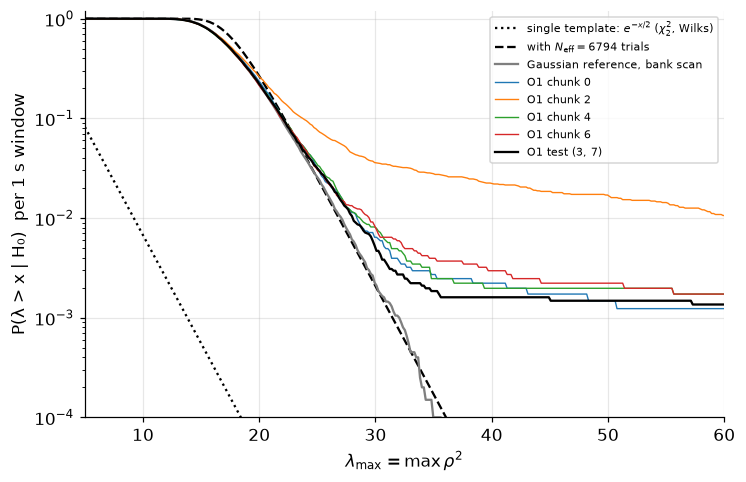

In [3]:
def survival(x, grid):
    xs = np.sort(x); return 1 - np.searchsorted(xs, grid, side="right") / len(xs)

grid = np.linspace(5, 70, 400)
sref = survival(ref["rho2"], grid)
sel = (sref < 0.5) & (sref > 2e-4)
def resid(logN): return np.log(1 - (1 - np.exp(-grid[sel] / 2)) ** np.exp(logN)) - np.log(sref[sel])
Neff = float(np.exp(optimize.least_squares(resid, np.log(300)).x[0]))
print("N_eff from the Gaussian reference: %.0f  (templates x time steps: %d x %d)" % (Neff, len(banks[0].grid), len(bkg_tr["taus"])))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.semilogy(grid, np.exp(-grid / 2), "k:", label=r"single template: $e^{-x/2}$ ($\chi^2_2$, Wilks)")
ax.semilogy(grid, 1 - (1 - np.exp(-grid / 2)) ** Neff, "k--", label=r"with $N_{\rm eff}=%.0f$ trials" % Neff)
ax.semilogy(grid, np.maximum(sref, 1e-5), color=g.COLORS["grey"], label="Gaussian reference, bank scan")
for i in g.SPLIT["train"]:
    s = survival(bkg_tr["rho2"][id_tr == i], grid); ax.semilogy(grid, np.maximum(s, 1e-5), lw=.9, label=f"O1 chunk {i}")
s = survival(bkg_te["rho2"], grid); ax.semilogy(grid, np.maximum(s, 1e-5), color="k", lw=1.5, label="O1 test (3, 7)")
ax.set_ylim(1e-4, 1.2); ax.set_xlim(5, 60)
ax.set_xlabel(r"$\lambda_{\max}=\max\rho^2$"); ax.set_ylabel("P(λ > x | H₀)  per 1 s window"); ax.legend(fontsize=7.5)
g.savefig(fig, "fig03_background"); plt.show()

What the figure says:

* The Gaussian-noise bank scan is perfectly described by $N_{\rm eff}\approx6800$ independent $\chi^2_2$ trials — the quantitative statement of the look-elsewhere effect: a *local* $\chi^2_2$ p-value must be multiplied by $\sim N_{\rm eff}$
  (a single-template threshold of $\lambda\approx9$ for FAP $10^{-2}$ becomes $\approx27$ for the bank).
* The real-noise curves follow the Gaussian prediction up to $\lambda\approx22$ and then **leave it**: they develop a long, nearly flat tail ("floor") at a few $10^{-3}$ that no
  Gaussian argument predicts — the loud glitches of notebook 01. The thresholds at FAP $10^{-2}$ and $10^{-3}$ are 33.6 and 114 on real data, against ≈27 and ≈31 for Gaussian noise with the same trials factor.
* The epochs differ enormously: chunk 2 is so glitchy that ~10 % of its windows exceed $\lambda=60$, and it dominates the training background; the test chunks (3, 7) are comparable to the cleaner training chunks.

## 2. Thresholds and calibration on unseen chunks## 2. Thresholds and calibration on unseen chunks

The threshold at false-alarm probability (FAP) $\alpha$ per window is the $(1-\alpha)$ quantile of the *train* background. The
test chunks come from different epochs (and different PSDs): the observed FAP there is a genuine test of the calibration.

In [4]:
ep = g.ExcessPower().fit(v_tr)
stat_bkg = {"bank": (bkg_tr["rho2"], bkg_te["rho2"]), "excess power": (ep.stat(v_tr), ep.stat(v_te))}
from scipy.stats import beta
def cp(k, n, cl=0.6827):
    a = (1 - cl) / 2
    return (beta.ppf(a, k, n - k + 1) if k > 0 else 0.0, beta.ppf(1 - a, k + 1, n - k))
rows = []
for name, (tr, te) in stat_bkg.items():
    for far in (1e-2, 1e-3):
        thr = g.threshold_at_far(tr, far)
        for lab, mask in (("test 3", id_te == 3), ("test 7", id_te == 7), ("test all", np.ones(len(te), bool))):
            k = int((te[mask] > thr).sum()); n = int(mask.sum()); lo, hi = cp(k, n)
            rows.append(dict(statistic=name, FAP_target=far, threshold=thr, set=lab, n=n, observed=k / n, lo68=lo, hi68=hi))
cal = pd.DataFrame(rows); cal

,statistic,FAP_target,threshold,set,n,observed,lo68,hi68
0,bank,0.010,33.636894,test 3,4056,0.001726,0.001090,0.002654
1,bank,0.010,33.636894,test 7,4056,0.002712,0.001907,0.003799
2,bank,0.010,33.636894,test all,8112,0.002219,0.001701,0.002874
3,bank,0.001,114.176534,test 3,4056,0.000986,0.000514,0.001765
4,bank,0.001,114.176534,test 7,4056,0.001479,0.000893,0.002362
5,bank,0.001,114.176534,test all,8112,0.001233,0.000850,0.001758
6,excess power,0.010,8.119728,test 3,4056,0.002219,0.001494,0.003231
7,excess power,0.010,8.119728,test 7,4056,0.005178,0.004059,0.006567
8,excess power,0.010,8.119728,test all,8112,0.003698,0.003028,0.004502
9,excess power,0.001,29.626789,test 3,4056,0.000740,0.000337,0.001459


The thresholds are **conservative** on the test epochs: at the nominal FAP of $10^{-2}$ the bank raises $2.2\times10^{-3}$ false alarms (binomial 68 % interval 1.7–2.9 $\times10^{-3}$), a factor ≈4.5 below target; at $10^{-3}$ the observed value is $1.2\times10^{-3}$ and consistent.
The reason is the glitchy chunk 2, which inflates the training background and hence the threshold. The lesson is the opposite of what one might expect from a Gaussian-noise analysis: the false-alarm probability is **not** a property of the statistic but of the (non-stationary) background it is calibrated on, and a
threshold carried to another epoch can be off by a factor of several in either direction. A real search estimates the background close in time to the data (time slides, rolling PSD).

## 3. Detection efficiency and ROC

For each morphology and SNR we inject 500 bursts into randomly chosen **test** windows (with the PSD of their own chunk) and count
the fraction above threshold. Three statistics are compared:

* **oracle** — $|z|^2$ at the *true* $(t_0,f_0,Q)$: the Neyman–Pearson optimal test of the simple hypothesis (not available in practice; sine-Gaussian only);
* **bank** — $\lambda_{\max}$ above, the profile-likelihood ratio;
* **excess power** — maximum over time and five durations (10–200 ms) of the z-scored band energy, which assumes nothing about the morphology.

In [5]:
# oracle background: random SG parameter draw per window, true-template statistic on the train noise
p_or = g.draw_params("sg", rng, len(v_tr))
or_bkg = g.exact_template_stat(g.to_bins(v_tr), p_or, S1_tr)

SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]
NINJ = 500
inj = {}
t0_ = time.time()
for kind in g.MORPHS:
    for snr in SNRS:
        idx = rng.choice(len(v_te), NINJ, replace=False)
        ser, p, _ = g.inject(v_te[idx], kind, float(snr), rng, S1_te[idx])
        d = {"bank": g.scan_mixed(ser, id_te[idx], banks)["rho2"], "excess power": ep.stat(ser)}
        if kind == "sg":
            d["oracle"] = g.exact_template_stat(g.to_bins(ser), p, S1_te[idx])
        inj[(kind, snr)] = d
print("injections done in %.0f s" % (time.time() - t0_))

injections done in 60 s


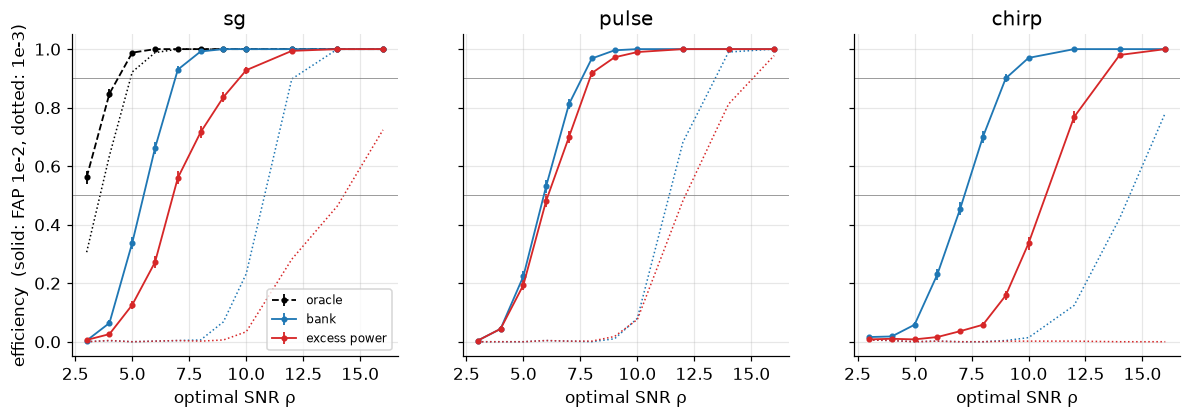

,morphology,statistic,rho50,rho50_err,rho90,rho90_err
0,sg,oracle,3.000000,0.000000,4.371429,0.085553
1,sg,bank,5.500000,0.065292,6.888060,0.046708
2,sg,excess power,6.791667,0.075422,9.695652,0.142611
3,pulse,bank,5.896104,0.071223,7.564103,0.077579
4,pulse,excess power,6.082569,0.099183,7.917431,0.059484
5,chirp,bank,7.186992,0.089169,9.000000,0.123285
6,chirp,excess power,10.759259,0.093849,13.245283,0.104349


In [6]:
thr = {far: {"bank": g.threshold_at_far(bkg_tr["rho2"], far), "excess power": g.threshold_at_far(stat_bkg["excess power"][0], far),
             "oracle": g.threshold_at_far(or_bkg, far)} for far in (1e-2, 1e-3)}
def eff_curve(kind, stat, far):
    e = np.array([g.efficiency(inj[(kind, s)][stat], thr[far][stat]) for s in SNRS]); return e[:, 0], e[:, 1]

def snr_at(eff, err, level):
    x = np.array(SNRS, float)
    f = lambda e: np.interp(level, np.maximum.accumulate(e), x) if e.max() >= level else np.nan
    return f(eff), f(eff + err), f(eff - err)

sty = {"oracle": ("k", "--"), "bank": (g.COLORS["freq"], "-"), "excess power": (g.COLORS["bayes"], "-")}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
rows = []
for a, kind in zip(ax, g.MORPHS):
    for stat in ("oracle", "bank", "excess power"):
        if stat == "oracle" and kind != "sg": continue
        e, er = eff_curve(kind, stat, 1e-2)
        a.errorbar(SNRS, e, er, color=sty[stat][0], ls=sty[stat][1], marker="o", ms=3, lw=1.2, label=stat)
        e3, _ = eff_curve(kind, stat, 1e-3); a.plot(SNRS, e3, color=sty[stat][0], ls=":", lw=1)
        r50, r50u, r50d = snr_at(e, er, 0.5); r90, r90u, r90d = snr_at(e, er, 0.9)
        rows.append(dict(morphology=kind, statistic=stat, rho50=r50, rho50_err=abs(r50u - r50d) / 2, rho90=r90, rho90_err=abs(r90u - r90d) / 2))
    a.set_title(kind); a.set_xlabel("optimal SNR ρ"); a.axhline(.9, color="grey", lw=.5); a.axhline(.5, color="grey", lw=.5)
ax[0].set_ylabel("efficiency  (solid: FAP 1e-2, dotted: 1e-3)"); ax[0].legend(fontsize=8)
g.savefig(fig, "fig03_efficiency"); plt.show()
eff_tab = pd.DataFrame(rows); eff_tab

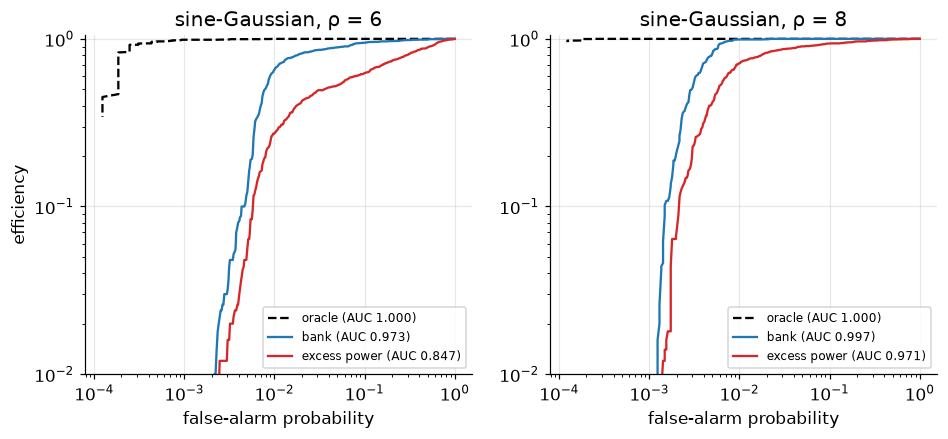

statistic,bank,excess power,oracle
morphology,,,
chirp,0.983347,0.819735,NaN
pulse,0.995100,0.994115,NaN
sg,0.996538,0.970755,0.99993


In [7]:
# ROC of the three statistics at rho = 6 and 8 for sine-Gaussians; AUC for all morphologies at rho = 8
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, snr in zip(ax, (6, 8)):
    for stat in ("oracle", "bank", "excess power"):
        b = {"oracle": or_bkg, "bank": bkg_tr["rho2"], "excess power": stat_bkg["excess power"][0]}[stat]
        far, eff = g.roc(b, inj[("sg", snr)][stat])
        a.loglog(far, np.maximum(eff, 1e-3), color=sty[stat][0], ls=sty[stat][1], label=f"{stat} (AUC {g.auc(b, inj[('sg', snr)][stat]):.3f})")
    a.set_title(f"sine-Gaussian, ρ = {snr}"); a.set_xlabel("false-alarm probability"); a.set_ylim(1e-2, 1.05); a.legend(fontsize=8)
ax[0].set_ylabel("efficiency")
g.savefig(fig, "fig03_roc"); plt.show()
auc_tab = pd.DataFrame([{"morphology": k, "statistic": s, "AUC(rho=8)": g.auc({"oracle": or_bkg, "bank": bkg_tr["rho2"], "excess power": stat_bkg["excess power"][0]}[s], inj[(k, 8)][s])}
                        for k in g.MORPHS for s in ("oracle", "bank", "excess power") if s in inj[(k, 8)]])
auc_tab.pivot(index="morphology", columns="statistic", values="AUC(rho=8)")

Reading the curves (FAP $10^{-2}$, solid):

* **Sine-Gaussian.** The oracle (true parameters known, Neyman–Pearson optimal) reaches 50 % efficiency at $\rho\approx3.0$ and 90 % at 4.4; the bank at 5.5 and 6.9; the excess-power statistic at 6.8 and 9.7. The gap oracle→bank is the look-elsewhere penalty (the price of not knowing $t_0,f_0,Q$);
  the gap bank→excess power is the price of not using the signal shape.
* **Pulse and chirp (outside the template family).** The bank is *mismatched* but still beats the agnostic statistic: the Gaussian pulse is well covered by low-frequency, low-$Q$ templates (ρ₅₀ 5.9 against 6.1) and the chirp loses only ≈1.7 in ρ₅₀ with respect to the sine-Gaussian (7.2) while excess power needs 10.8.
  Neither is optimal there, which is the motivation for the machine-learning detectors of notebook 05.
* **FAP $10^{-3}$ (dotted).** Because of the glitch floor, lowering the FAP by a factor of 10 costs *much* more than in Gaussian noise: the 50 % point of the bank moves from ρ ≈ 5.5 to ≈ 11. ROC AUC at ρ = 8: sine-Gaussian 0.997 / 0.971 (bank / excess power), pulse 0.995 / 0.994, chirp 0.983 / 0.820.

## 4. Maximum-likelihood parameter estimation

For a detected sine-Gaussian we refine the bank maximum with `iminuit` on the continuous profile $\rho^2(t_0,f_0,Q)$ (exact analytic template, amplitude and phase profiled).
The covariance of the MLE is compared with the **Fisher / Cramér–Rao** matrix computed from the Hessian of $-\rho^2$ at the truth on noise-free data:
$\mathrm{cov}=2\,[\nabla^2(-\rho^2)]^{-1}$ (because $-\rho^2=-2\ln\mathcal L_p$).

In [8]:
def template(f0, Q, t0, S1):
    T = 2 * g.sine_gaussian_ft(g.FREQ, f0, Q, 0.0, positive_only=True) * np.exp(-2j*np.pi*g.FREQ*t0) / np.sqrt(S1) * g.BAND
    return T / np.sqrt(np.sum(np.abs(T)**2))
def rho2_cont(X, S1, t0, f0, Q):
    return np.abs(np.sum(X * np.conj(template(f0, Q, t0, S1)))) ** 2

TRUE = dict(t0=0.5, f0=150.0, Q=8.0)
S1c = CH[3]["S1"]
def fisher(snr, h=(1e-4, 0.05, 0.02)):
    # noise-free data at SNR snr, Hessian of -rho^2 by central finite differences
    p = {k: np.array([v]) for k, v in dict(TRUE, phi=0.0).items()}
    X = g.waveform_bins("sg", p, S1c)[0]; X = X * snr / g.snr_of(X)
    th0 = np.array([TRUE["t0"], TRUE["f0"], TRUE["Q"]])
    F = lambda th: -rho2_cont(X, S1c, *th)
    H = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            ei, ej = np.eye(3)[i] * h[i], np.eye(3)[j] * h[j]
            H[i, j] = (F(th0+ei+ej) - F(th0+ei-ej) - F(th0-ei+ej) + F(th0-ei-ej)) / (4*h[i]*h[j])
    return 2 * np.linalg.inv(H)

def mle(X, S1, start):
    m = Minuit(lambda t0, f0, Q: -rho2_cont(X, S1, t0, f0, Q), t0=start[0], f0=start[1], Q=start[2])
    m.errordef = Minuit.LEAST_SQUARES
    m.limits = [(0.1, 0.9), (30, 500), (2, 25)]
    m.migrad()
    return m

pe_rows, pulls = [], {}
t0_ = time.time()
SNR_PE = [6, 8, 10, 15, 20, 30]
for snr in SNR_PE:
    idx = rng.choice(len(v_te[id_te == 3]), 300, replace=False)
    v3 = v_te[id_te == 3][idx]
    p = {k: np.full(300, v) for k, v in dict(TRUE, phi=0.0).items()}
    p["phi"] = rng.uniform(0, 2*np.pi, 300)
    ser, _, _ = g.inject(v3, "sg", float(snr), rng, S1c, params=p)
    Xb = g.to_bins(ser)
    sc = banks[3].scan(Xb)
    est = np.zeros((300, 3)); err = np.zeros((300, 3)); rho_hat = np.zeros(300)
    for n in range(300):
        m = mle(Xb[n], S1c, (sc["tau"][n], sc["f0"][n], sc["Q"][n]))
        est[n] = m.values; err[n] = m.errors; rho_hat[n] = np.sqrt(-m.fval)
    cov = fisher(snr)
    truth = np.array([TRUE["t0"], TRUE["f0"], TRUE["Q"]])
    for j, nm in enumerate(["t0", "f0", "Q"]):
        d = est[:, j] - truth[j]
        pe_rows.append(dict(snr=snr, par=nm, bias=d.mean(), rms=d.std(), median_abs_dev=1.4826*np.median(np.abs(d - np.median(d))),
                            fisher_sigma=np.sqrt(cov[j, j]), hesse_sigma_median=np.median(err[:, j])))
    pulls[snr] = (est - truth) / err
    pe_rows.append(dict(snr=snr, par="rho_hat", bias=(rho_hat - snr).mean(), rms=(rho_hat - snr).std(), fisher_sigma=1.0))
print("PE time %.0f s" % (time.time() - t0_))
pe = pd.DataFrame(pe_rows); pe

PE time 20 s


,snr,par,bias,rms,median_abs_dev,fisher_sigma,hesse_sigma_median
0,6,t0,0.000797,0.036247,0.002181,0.002031,0.001928
1,6,f0,4.054419,33.948377,5.047467,4.487958,4.499111
2,6,Q,0.414253,3.349692,2.269972,1.964417,1.775398
3,6,rho_hat,0.504481,0.961084,NaN,1.000000,NaN
4,8,t0,0.000855,0.015898,0.001642,0.001523,0.001524
5,8,f0,-0.177644,4.216979,4.004639,3.365968,3.379618
6,8,Q,0.203724,2.001175,1.563931,1.473312,1.405494
7,8,rho_hat,0.404948,2.915628,NaN,1.000000,NaN
8,10,t0,-0.000010,0.001315,0.001388,0.001219,0.001240
9,10,f0,-0.088452,2.805325,2.379229,2.692775,2.633689


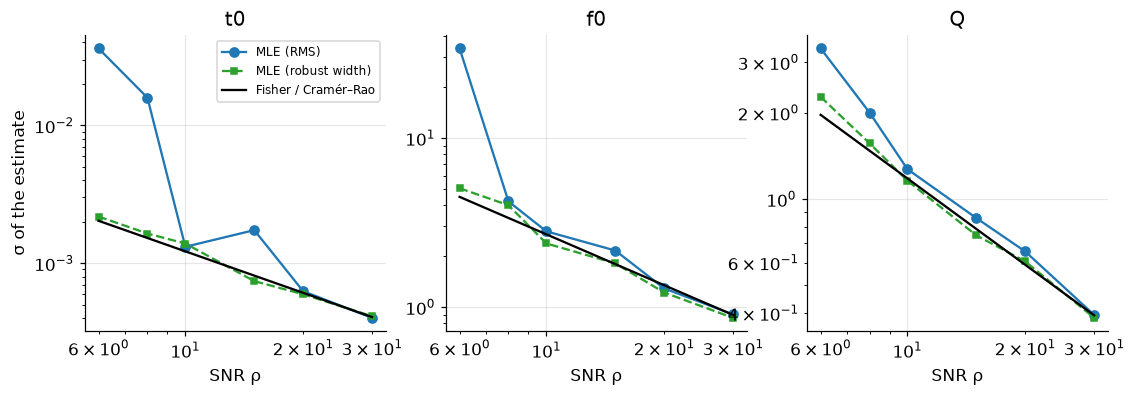

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, nm in zip(ax, ["t0", "f0", "Q"]):
    d = pe[pe.par == nm]
    a.loglog(d.snr, d.rms, "o-", color=g.COLORS["freq"], label="MLE (RMS)")
    a.loglog(d.snr, d.median_abs_dev, "s--", color=g.COLORS["ml"], ms=4, label="MLE (robust width)")
    a.loglog(d.snr, d.fisher_sigma, "k-", label="Fisher / Cramér–Rao")
    a.set_xlabel("SNR ρ"); a.set_title(nm)
ax[0].set_ylabel("σ of the estimate"); ax[0].legend(fontsize=8)
g.savefig(fig, "fig03_pe_fisher"); plt.show()

At high SNR the MLE saturates the Cramér–Rao bound (the MLE is asymptotically efficient and Gaussian); as the SNR decreases the RMS departs upward because the
likelihood surface develops secondary maxima (the estimate jumps to a noise peak) — the typical threshold effect of non-linear parameters. The robust width tracks the Fisher
prediction further down than the RMS does.

## 5. Toy Monte Carlo of the amplitude estimate

Fix the template (the parameters $t_0,f_0,Q$ are known) and estimate the SNR $s\ge0$ from $z=s\,e^{i\varphi}+n$, $n\sim\mathcal N(0,I_2)$.
Profiling the phase, the maximum-likelihood estimator is $\hat s=|z|$ (Rice distribution) and $-2\Delta\ln\mathcal L_p(s)=(\hat s-s)^2$:
the "68 % profile-likelihood interval" is $[\hat s-1,\hat s+1]$, truncated at 0. We study its bias, pulls and coverage and compare with the
exact Neyman construction with central ordering and with the Feldman–Cousins ordering.

In [10]:
S_GRID = np.linspace(0, 10, 41)
NT = 40000
rice = lambda x, s: x * special.i0e(x * s) * np.exp(-(x - s) ** 2 / 2)       # Rice pdf (unit-variance quadratures)

# Neyman belts on a fine grid of shat
xg = np.linspace(0, 20, 8001); dx = xg[1] - xg[0]
CL = 0.6827
def belt(s, kind):
    pdf = rice(xg, s)
    if kind == "central":
        cdf = np.cumsum(pdf) * dx
        return xg[np.searchsorted(cdf, (1 - CL) / 2)], xg[np.searchsorted(cdf, 1 - (1 - CL) / 2)]
    R = pdf / np.maximum(rice(xg, xg), 1e-300)          # likelihood ratio ordering, s_best(x) = x (s >= 0)
    order = np.argsort(-R); cum = np.cumsum(pdf[order]) * dx
    acc = order[: np.searchsorted(cum, CL) + 1]
    return xg[acc.min()], xg[acc.max()]

lo_c, hi_c = np.array([belt(s, "central") for s in S_GRID]).T
lo_f, hi_f = np.array([belt(s, "fc") for s in S_GRID]).T

rows = []; pull_store = {}
for s in S_GRID:
    z = s * np.exp(2j*np.pi*rng.uniform(size=NT)) + rng.normal(size=NT) + 1j*rng.normal(size=NT)
    sh = np.abs(z)
    prof = np.mean(np.abs(sh - s) <= 1.0)
    cen = np.mean((sh >= np.interp(s, S_GRID, lo_c)) & (sh <= np.interp(s, S_GRID, hi_c)))
    fc = np.mean((sh >= np.interp(s, S_GRID, lo_f)) & (sh <= np.interp(s, S_GRID, hi_f)))
    rows.append(dict(s=s, bias=sh.mean() - s, rms=sh.std(), cov_profile=prof, cov_central=cen, cov_fc=fc))
    pull_store[s] = sh - s
toy = pd.DataFrame(rows)
toy.iloc[::4]

,s,bias,rms,cov_profile,cov_central,cov_fc
0,0.0,1.253732,0.654293,0.394550,0.684500,0.682175
4,1.0,0.550311,0.778043,0.732200,0.684125,0.683375
8,2.0,0.273865,0.909460,0.706100,0.686050,0.685650
12,3.0,0.172153,0.963325,0.690850,0.682300,0.682150
16,4.0,0.130869,0.975251,0.689100,0.685375,0.685375
20,5.0,0.100511,0.995625,0.682300,0.678725,0.678000
24,6.0,0.080394,0.990304,0.687650,0.686275,0.685550
28,7.0,0.071715,0.991940,0.683300,0.684025,0.683400
32,8.0,0.060666,0.996809,0.681200,0.681300,0.680450
36,9.0,0.051050,1.006492,0.677300,0.677775,0.677775


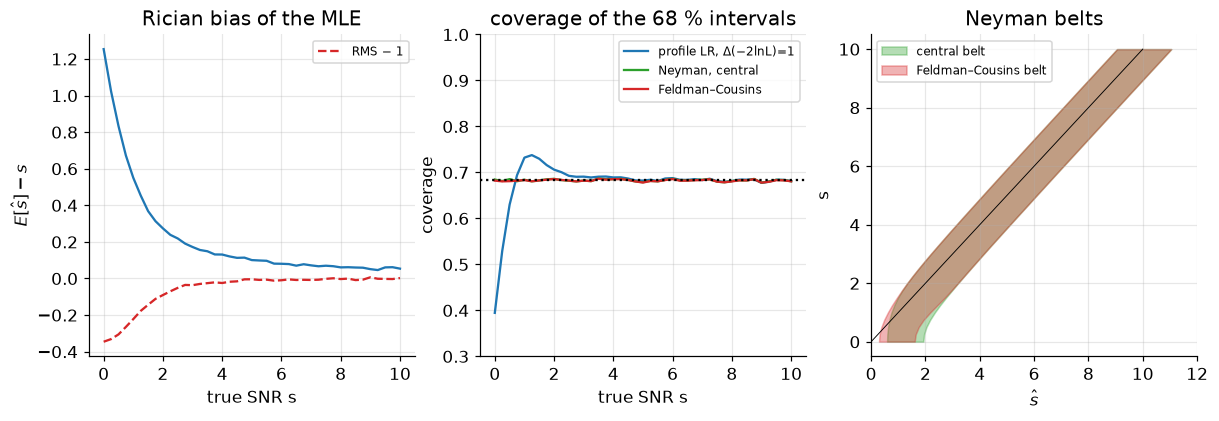

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(toy.s, toy.bias, color=g.COLORS["freq"]); ax[0].set_xlabel("true SNR s"); ax[0].set_ylabel(r"$E[\hat s]-s$"); ax[0].set_title("Rician bias of the MLE")
ax[0].plot(toy.s, toy.rms - 1, color=g.COLORS["bayes"], ls="--", label="RMS − 1"); ax[0].legend(fontsize=8)
for k, lab, c in (("cov_profile", "profile LR, Δ(−2lnL)=1", g.COLORS["freq"]), ("cov_central", "Neyman, central", g.COLORS["ml"]), ("cov_fc", "Feldman–Cousins", g.COLORS["bayes"])):
    ax[1].plot(toy.s, toy[k], label=lab, color=c)
ax[1].axhline(CL, color="k", ls=":"); ax[1].set_ylim(0.3, 1); ax[1].set_xlabel("true SNR s"); ax[1].set_ylabel("coverage"); ax[1].legend(fontsize=8)
ax[1].set_title("coverage of the 68 % intervals")
ax[2].fill_betweenx(S_GRID, lo_c, hi_c, color=g.COLORS["ml"], alpha=.35, label="central belt")
ax[2].fill_betweenx(S_GRID, lo_f, hi_f, color=g.COLORS["bayes"], alpha=.35, label="Feldman–Cousins belt")
ax[2].plot(S_GRID, S_GRID, "k", lw=.6); ax[2].set_xlim(0, 12); ax[2].set_xlabel(r"$\hat s$"); ax[2].set_ylabel("s"); ax[2].legend(fontsize=8)
ax[2].set_title("Neyman belts")
g.savefig(fig, "fig03_toys_amplitude"); plt.show()

Three lessons in one toy. (i) The MLE of an amplitude constrained to be positive and measured through its modulus is **biased upward** at low SNR
($E[\hat s]\to\sqrt{\pi/2}$ at $s=0$). (ii) The profile-likelihood interval has the correct 68 % coverage only asymptotically ($s\gtrsim3$), over-covers slightly around $s\approx1$ and
under-covers badly at $s\to0$ (39 % instead of 68 %), where Wilks' regularity conditions (parameter on the boundary) fail. (iii) The Neyman constructions cover by
construction; the Feldman–Cousins ordering gives upper limits at low $\hat s$ and two-sided intervals at high $\hat s$ without a
decision about "flip-flopping".

### The same estimate in real noise

Same fixed template, injected into real test windows: the estimator and its coverage must agree with the Gaussian toy if the noise is Gaussian enough.

In [12]:
rows = []
S_REAL = [0, 2, 4, 6, 8]
for s in S_REAL:
    idx = rng.choice(len(v_te), 5000, replace=False)
    p = {k: np.full(5000, v) for k, v in dict(TRUE, phi=0.0).items()}; p["phi"] = rng.uniform(0, 2*np.pi, 5000)
    ser = v_te[idx] if s == 0 else g.inject(v_te[idx], "sg", float(s), rng, S1_te[idx], params=p)[0]
    sh = np.sqrt(g.exact_template_stat(g.to_bins(ser), p, S1_te[idx]))
    ideal = toy.iloc[np.argmin(abs(toy.s - s))]
    rows.append(dict(s=s, bias_real=sh.mean() - s, bias_gauss=ideal.bias, rms_real=sh.std(), rms_gauss=ideal.rms,
                     cov_profile_real=np.mean(abs(sh - s) <= 1), cov_profile_gauss=ideal.cov_profile))
real_toy = pd.DataFrame(rows); real_toy

,s,bias_real,bias_gauss,rms_real,rms_gauss,cov_profile_real,cov_profile_gauss
0,0,1.241326,1.253732,0.648095,0.654293,0.3926,0.39455
1,2,0.277665,0.273865,0.910279,0.909460,0.7134,0.70610
2,4,0.128455,0.130869,0.973276,0.975251,0.6900,0.68910
3,6,0.106867,0.080394,1.003007,0.990304,0.6726,0.68765
4,8,0.069792,0.060666,0.990699,0.996809,0.6860,0.68120


## 6. Systematic study

Observable: the sine-Gaussian efficiency $\varepsilon(\rho=8)$ at FAP = 10⁻². Each variant changes **one** analysis choice, recomputes the
whole chain (PSD, whitening, bank, threshold on chunks 0 and 2, efficiency on chunks 3 and 7) and uses the **same noise windows and injection parameters** as the nominal analysis, so the
differences are correlated. Barlow's criterion: $\Delta=\varepsilon_{\rm var}-\varepsilon_{\rm nom}$ with
$\sigma_\Delta=\sqrt{|\sigma^2_{\rm var}-\sigma^2_{\rm nom}|}$; a variation is significant if $|\Delta|/\sigma_\Delta>2$. We also report the paired standard error, which is the appropriate
one for the identical-sample design, and the variation of the threshold itself.

In [13]:
VARIANTS = {
    "nominal": dict(),
    "PSD mean-average": dict(psd_kw={"average": "mean"}),
    "PSD 2 s segments": dict(psd_kw={"nperseg_s": 2.0}),
    "PSD 8 s segments": dict(psd_kw={"nperseg_s": 8.0}),
    "band 20-500 Hz": dict(band=(20, 500)),
    "band 30-400 Hz": dict(band=(30, 400)),
    "coarse bank (20 f0)": dict(bank_kw={"f0s": np.geomspace(40, 450, 20)}),
}
FAP_SYS, SNR_SYS, N_SYS = 1e-2, 8.0, 1000

def run_variant(psd_kw=None, band=g.FBAND, bank_kw=None):
    ch = {i: g.load_chunk(i, psd_kw=psd_kw, band=band) for i in (0, 2, 3, 7)}
    bm = g.band_mask(*band)
    bk = {i: g.SGBank(ch[i]["S1"], band=bm, **(bank_kw or {})) for i in ch}
    vb = np.concatenate([ch[0]["v"], ch[2]["v"]]); ib = np.concatenate([np.full(len(ch[0]["v"]), 0), np.full(len(ch[2]["v"]), 2)])
    thr_ = g.threshold_at_far(g.scan_mixed(vb, ib, bk, band=bm)["rho2"], FAP_SYS)
    vt = np.concatenate([ch[3]["v"], ch[7]["v"]]); it = np.concatenate([np.full(len(ch[3]["v"]), 3), np.full(len(ch[7]["v"]), 7)])
    S1t = np.stack([ch[i]["S1"] for i in it])
    r = np.random.default_rng(99)                                  # identical windows and injections for every variant
    idx = r.choice(len(vt), N_SYS, replace=False)
    ser, _, _ = g.inject(vt[idx], "sg", SNR_SYS, r, S1t[idx], band=bm)
    hit = g.scan_mixed(ser, it[idx], bk, band=bm)["rho2"] > thr_
    return thr_, hit

fn = os.path.join(g.RESULTS, "03_systematics_raw.json")
store = json.load(open(fn)) if os.path.exists(fn) else {}
t0_ = time.time()
for name, kw in VARIANTS.items():
    if name in store: continue
    thr_, hit = run_variant(**kw)
    store[name] = dict(threshold=float(thr_), hits=hit.astype(int).tolist())
    json.dump(store, open(fn, "w"))
print("systematics time %.0f s" % (time.time() - t0_))

nom = np.array(store["nominal"]["hits"]); e0 = nom.mean(); s0 = np.sqrt(e0 * (1 - e0) / N_SYS)
rows = []
for name in VARIANTS:
    h = np.array(store[name]["hits"]); e = h.mean(); s = np.sqrt(e * (1 - e) / N_SYS)
    d = e - e0; sd = np.sqrt(abs(s**2 - s0**2)); sp = (h - nom).std() / np.sqrt(N_SYS)
    rows.append(dict(variant=name, threshold=store[name]["threshold"], eff=e, delta=d, sigma_barlow=sd, n_sigma_barlow=(abs(d) / sd if sd > 0 else 0.0),
                     sigma_paired=sp, n_sigma_paired=(abs(d) / sp if sp > 0 else 0.0)))
sysd = pd.DataFrame(rows); sysd

systematics time 0 s


,variant,threshold,eff,delta,sigma_barlow,n_sigma_barlow,sigma_paired,n_sigma_paired
0,nominal,44.990874,0.928,0.000,0.000000,0.000000,0.000000,0.000000
1,PSD mean-average,42.917389,0.953,0.025,0.004693,5.326992,0.004937,5.063697
2,PSD 2 s segments,44.641776,0.935,0.007,0.002458,2.848024,0.002992,2.339711
3,PSD 8 s segments,44.642630,0.933,0.005,0.002075,2.409813,0.002996,1.668986
4,band 20-500 Hz,44.977884,0.929,0.001,0.000926,1.080213,0.000999,1.000500
5,band 30-400 Hz,44.997973,0.925,-0.003,0.001600,1.875366,0.001729,1.734655
6,coarse bank (20 f0),44.010758,0.921,-0.007,0.002438,2.871410,0.004577,1.529310


Only one choice produces a variation that is large and unambiguously significant: using the **mean** instead of the median in the Welch average, which raises the efficiency by $+0.025$ (≈5σ in both the Barlow and the paired estimate) because the mean PSD is inflated by glitches
and lowers the whitened-noise level, hence the threshold (42.9 against 45.0). All other variants (PSD segment length, band edges, bank resolution) change the efficiency by at most 0.007, at the 1–3σ level.
We therefore quote a systematic uncertainty of **0.025 on ε(ρ=8)** (the largest variation), dominated by the PSD estimator.

## Summary

In [14]:
sys_unc = float(np.max(np.abs(sysd.delta[1:]))) if len(sysd) > 1 else 0.0
summary = dict(
    N_eff=Neff, n_bank=len(banks[0].grid), n_train_windows=len(v_tr), n_test_windows=len(v_te),
    thresholds={str(f): {k: float(v) for k, v in d.items()} for f, d in thr.items()},
    calibration=cal.to_dict("records"),
    efficiency_table=eff_tab.to_dict("records"),
    auc_rho8=auc_tab.to_dict("records"),
    eff_curves={f"{k}/{s}": dict(snr=SNRS, eff=eff_curve(k, s, 1e-2)[0].tolist()) for k in g.MORPHS for s in ("bank", "excess power", "oracle") if s in inj[(k, 8)]},
    pe=pe.to_dict("records"),
    toy_amplitude=toy.to_dict("records"), toy_real=real_toy.to_dict("records"),
    systematics=sysd.to_dict("records"), sys_max_delta_eff=sys_unc)
g.save_json(summary, "03_summary.json")
print("N_eff = %.0f; max systematic variation of eff(rho=8) = %.3f" % (Neff, sys_unc))

N_eff = 6794; max systematic variation of eff(rho=8) = 0.025


## Output and next step

* `results/03_summary.json` (all numbers quoted in the report), `results/03_systematics_raw.json` (per-injection outcomes of the variants), `figures/fig03_*`.
* The scans are cached in `cache/scan03_*.npz`; the systematic study resumes from `results/03_systematics_raw.json`.

Next: **`04_bayesian_analysis.ipynb`** — the same likelihood, now with priors: posterior of the burst parameters, Bayes factors, calibration of the credible intervals.